In [ ]:
#Import Library
import os
import sys
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    pairwise_distances
)

from google.colab import drive
drive.mount('/content/drive')

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

OUTPUT_DIR = "/content/drive/MyDrive/ml-semester5/KUIS-1/outputKmeans"
os.makedirs(OUTPUT_DIR, exist_ok=True)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("[INFO] Library berhasil diinstall.")
print(f"[INFO] Folder output: '{OUTPUT_DIR}' | Random state: {RANDOM_STATE}")

Mounted at /content/drive
[INFO] Library berhasil diinstall.
[INFO] Folder output: '/content/drive/MyDrive/ml-sem5/kuis1/outputKmeans' | Random state: 42


In [ ]:
# Load Dataset
df_raw = pd.read_csv('/content/drive/MyDrive/ml-sem5/kuis1/dataset/diabetes_binary_5050split_health_indicators_BRFSS2015.csv')
print(f"Data awal: {df_raw.shape[0]} baris x {df_raw.shape[1]} kolom")
df_raw.head()

Data awal: 70692 baris x 22 kolom


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,3.0,5.0,30.0,0.0,1.0,4.0,6.0,8.0
1,0.0,1.0,1.0,1.0,26.0,1.0,1.0,0.0,0.0,1.0,...,1.0,0.0,3.0,0.0,0.0,0.0,1.0,12.0,6.0,8.0
2,0.0,0.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,10.0,0.0,1.0,13.0,6.0,8.0
3,0.0,1.0,1.0,1.0,28.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,3.0,0.0,3.0,0.0,1.0,11.0,6.0,8.0
4,0.0,0.0,0.0,1.0,29.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,8.0,5.0,8.0


In [ ]:
# Cek data awal
print("Tipe data tiap kolom:")
print(df_raw.dtypes.value_counts())

print("\nTotal missing value per kolom (hanya yang > 0):")
missing = df_raw.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else "Tidak ada missing value")

print(f"\nJumlah baris duplikat: {df_raw.duplicated().sum()}")

print("\nSebaran kelas Diabetes_binary (0=tidak, 1=diabetes):")
print(df_raw['Diabetes_binary'].value_counts().sort_index())

Tipe data tiap kolom:
float64    22
Name: count, dtype: int64

Total missing value per kolom (hanya yang > 0):
Tidak ada missing value

Jumlah baris duplikat: 1635

Sebaran kelas Diabetes_binary (0=tidak, 1=diabetes):
Diabetes_binary
0.0    35346
1.0    35346
Name: count, dtype: int64


In [ ]:
# preprocessing
LABEL = 'Diabetes_binary'          # label sudah 0 dan 1
FITUR_DIBUANG = ['Income','CholCheck', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'Education']         # tambahkan fitur lain yang kamu buang sampai tersisa 15 fitur

df = df_raw.copy()
print(f"Data awal: {len(df)} baris x {df.shape[1]} kolom")
print(f"Sebaran kelas awal: {df[LABEL].value_counts().sort_index().to_dict()}")

df = df.drop(columns=FITUR_DIBUANG)
print(f"Setelah buang fitur       : {df.shape[1]} kolom (termasuk label)")

n_sebelum_dup = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Setelah hapus duplikat    : {len(df)} baris (terbuang {n_sebelum_dup - len(df)})")
print(f"Sebaran kelas akhir       : {df[LABEL].value_counts().sort_index().to_dict()}")

y_label = df[LABEL].copy()   # label hanya untuk pembanding, tidak dipakai klastering
df_features = df.drop(columns=[LABEL]).astype(float)
print(f"Jumlah fitur untuk klastering: {df_features.shape[1]}")
print(f"Daftar fitur: {list(df_features.columns)}")

scaler = StandardScaler()
X_all = scaler.fit_transform(df_features.values)
X_scaled = X_all
print(f"Bentuk data siap klaster: {X_all.shape}")
print(f"Cek mean 0 dan std 1: {X_all.mean():.4f} / {X_all.std():.4f}")

Data awal: 70692 baris x 22 kolom
Sebaran kelas awal: {0.0: 35346, 1.0: 35346}
Setelah buang fitur       : 16 kolom (termasuk label)
Setelah hapus duplikat    : 63197 baris (terbuang 7495)
Sebaran kelas akhir       : {0.0: 29885, 1.0: 33312}
Jumlah fitur untuk klastering: 15
Daftar fitur: ['HighBP', 'HighChol', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age']
Bentuk data siap klaster: (63197, 15)
Cek mean 0 dan std 1: 0.0000 / 1.0000


In [ ]:
# Class Kmeans
class KMeansManhattan:
    """K-Means dengan jarak Manhattan (L1). Centroid diupdate pakai median per dimensi."""
    def __init__(self, n_clusters=3, max_iter=300, tol=1e-4, random_state=42):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = random_state
        self.centroids = None
        self.labels_ = None
        self.inertia_ = 0.0
        self.n_iter_ = 0
        self.execution_time_ = 0.0

    def _compute_distance(self, X, centroids):
        return pairwise_distances(X, centroids, metric='manhattan', n_jobs=-1)

    def _init_centroids(self, X):
        rng = np.random.RandomState(self.random_state)
        n_samples, _ = X.shape
        first_idx = rng.randint(n_samples)
        centroids = [X[first_idx]]

        for _ in range(1, self.n_clusters):
            cur_c = np.array(centroids)
            dists = self._compute_distance(X, cur_c)
            min_dists = np.min(dists, axis=1)
            sq_dists = min_dists ** 2
            sum_sq = np.sum(sq_dists)
            probs = np.ones(n_samples) / n_samples if sum_sq == 0 else sq_dists / sum_sq
            next_idx = rng.choice(n_samples, p=probs)
            centroids.append(X[next_idx])
        return np.array(centroids)

    def fit(self, X):
        start_time = time.perf_counter()
        self.centroids = self._init_centroids(X)

        for it in range(self.max_iter):
            self.n_iter_ = it + 1
            dists = self._compute_distance(X, self.centroids)
            labels = np.argmin(dists, axis=1)

            new_centroids = np.zeros_like(self.centroids)
            rng = np.random.RandomState(self.random_state)
            for k in range(self.n_clusters):
                cluster_pts = X[labels == k]
                if len(cluster_pts) == 0:
                    new_centroids[k] = X[rng.randint(len(X))]
                else:
                    new_centroids[k] = np.median(cluster_pts, axis=0)
            shift = np.linalg.norm(new_centroids - self.centroids)
            self.centroids = new_centroids
            self.labels_ = labels

            if shift < self.tol:
                break

        final_dists = self._compute_distance(X, self.centroids)
        assigned_dists = final_dists[np.arange(len(X)), self.labels_]
        self.inertia_ = float(np.sum(assigned_dists))
        self.execution_time_ = float(time.perf_counter() - start_time)
        return self

print("[INFO] Kelas KMeansManhattan berhasil diinisialisasi.")

[INFO] Kelas KMeansManhattan berhasil diinisialisasi.


  k = 1  | SAE = 661,251.7 | iterasi = 2
  k = 2  | SAE = 578,177.5 | iterasi = 7
  k = 3  | SAE = 520,612.3 | iterasi = 9
  k = 4  | SAE = 504,404.0 | iterasi = 5
  k = 5  | SAE = 485,708.6 | iterasi = 5
  k = 6  | SAE = 458,178.0 | iterasi = 6
  k = 7  | SAE = 442,440.9 | iterasi = 9
  k = 8  | SAE = 441,445.0 | iterasi = 8
  k = 9  | SAE = 436,103.1 | iterasi = 10
  k = 10 | SAE = 421,913.1 | iterasi = 10
[SIMPAN] Grafik Elbow disimpan ke: '/content/drive/MyDrive/ml-sem5/kuis1/outputKmeans/elbow_manhattan.png'


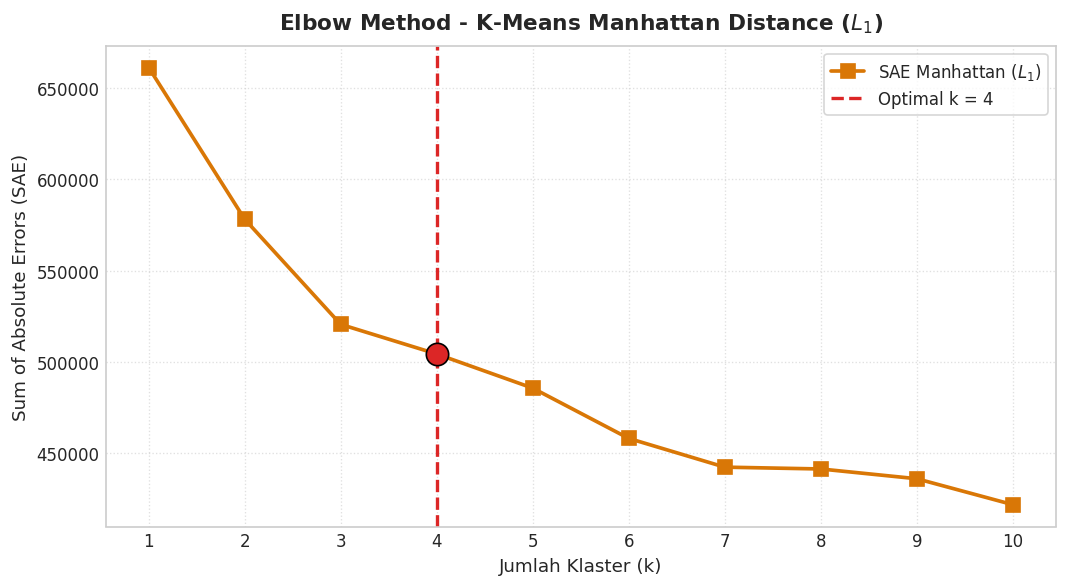

In [ ]:
# Elbow Manhattan
k_range = list(range(1, 11))
sae_manhattan = []

for k in k_range:
    km = KMeansManhattan(n_clusters=k, max_iter=200, random_state=RANDOM_STATE)
    km.fit(X_scaled)
    sae_manhattan.append(km.inertia_)
    print(f"  k = {k:<2} | SAE = {km.inertia_:,.1f} | iterasi = {km.n_iter_}")

def find_elbow_point(k_vals, inertias):
    p1 = np.array([k_vals[0], inertias[0]])
    p2 = np.array([k_vals[-1], inertias[-1]])
    line_vec = p2 - p1
    line_unit = line_vec / np.linalg.norm(line_vec)
    dists = [
        np.linalg.norm((np.array([k, s]) - p1) - np.dot(np.array([k, s]) - p1, line_unit) * line_unit)
        for k, s in zip(k_vals, inertias)
    ]
    return k_vals[int(np.argmax(dists))]

optimal_k = 4 # menggunakan k=4 untuk menyamakan parameter

plt.figure(figsize=(9, 5))
plt.plot(k_range, sae_manhattan, marker='s', markersize=8, linewidth=2.2, color='#D97706', label='SAE Manhattan ($L_1$)')
plt.axvline(x=optimal_k, color='#DC2626', linestyle='--', linewidth=2, label=f'Optimal k = {optimal_k}')
plt.scatter([optimal_k], [sae_manhattan[optimal_k - 1]], color='#DC2626', s=180, zorder=5, edgecolor='black')
plt.title('Elbow Method - K-Means Manhattan Distance ($L_1$)', fontsize=13, fontweight='bold', pad=10)
plt.xlabel('Jumlah Klaster (k)', fontsize=11)
plt.ylabel('Sum of Absolute Errors (SAE)', fontsize=11)
plt.xticks(k_range)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(frameon=True, facecolor='white')
plt.tight_layout()

elbow_path = os.path.join(OUTPUT_DIR, "elbow_manhattan.png")
plt.savefig(elbow_path, dpi=300)
print(f"[SIMPAN] Grafik Elbow disimpan ke: '{elbow_path}'")
plt.show()

In [ ]:
# Klastering Final
model_manhattan = KMeansManhattan(n_clusters=optimal_k, max_iter=300, tol=1e-4, random_state=RANDOM_STATE)
model_manhattan.fit(X_scaled)
labels = model_manhattan.labels_

sil_score = float(silhouette_score(X_scaled, labels, metric='manhattan', sample_size=10000, random_state=RANDOM_STATE))
db_score = float(davies_bouldin_score(X_scaled, labels))  # Davies-Bouldin (makin kecil makin bagus)
ch_score = float(calinski_harabasz_score(X_scaled, labels))  # Calinski-Harabasz (makin besar makin bagus)

eval_df = pd.DataFrame([{
    'Distance Metric': 'Manhattan Distance (L1)',
    'Optimal k': optimal_k,
    'Jumlah Data': X_scaled.shape[0],
    'Jumlah Fitur': X_scaled.shape[1],
    'Silhouette Score (↑)': round(sil_score, 4),
    'Davies–Bouldin Index (↓)': round(db_score, 4),
    'Calinski–Harabasz Index (↑)': round(ch_score, 2),
    'Execution Time (s) (↓)': round(model_manhattan.execution_time_, 5),
    'Iterations (↓)': model_manhattan.n_iter_,
    'Objective Value (SAE) (↓)': round(model_manhattan.inertia_, 2)
}])

print("\n" + "=" * 80)
print("TABEL EVALUASI K-MEANS MANHATTAN")
print("=" * 80)
print(eval_df.to_string(index=False))
print("=" * 80)

df_clustered = df_features.copy()
df_clustered[LABEL] = y_label.values  # tambah label asli
df_clustered['Cluster_Manhattan'] = labels  # tambah label klaster

profil = df_clustered.groupby('Cluster_Manhattan').mean().round(3)  # rata-rata tiap fitur per klaster
profil['Jumlah Data'] = df_clustered['Cluster_Manhattan'].value_counts().sort_index()  # jumlah anggota klaster
profil['% Diabetes'] = (df_clustered.groupby('Cluster_Manhattan')[LABEL].apply(lambda s: (s == 1).mean() * 100)).round(2)  # persen diabetes per klaster

excel_path = os.path.join(OUTPUT_DIR, "evaluasi_kmeans_manhattan.xlsx")
with pd.ExcelWriter(excel_path, engine='openpyxl') as writer:
    eval_df.to_excel(writer, sheet_name='Ringkasan_Evaluasi', index=False)  # sheet 1: evaluasi
    profil.to_excel(writer, sheet_name='Profil_Klaster')  # sheet 2: profil klaster
print(f"[SIMPAN] Evaluasi & profil klaster disimpan ke: '{excel_path}'")

csv_path = os.path.join(OUTPUT_DIR, "data_terklaster_manhattan.csv")
df_clustered.to_csv(csv_path, index=False)  # simpan data + label klaster (CSV lebih ringan)
print(f"[SIMPAN] Data terklaster disimpan ke: '{csv_path}'")




TABEL EVALUASI K-MEANS MANHATTAN
        Distance Metric  Optimal k  Jumlah Data  Jumlah Fitur  Silhouette Score (↑)  Davies–Bouldin Index (↓)  Calinski–Harabasz Index (↑)  Execution Time (s) (↓)  Iterations (↓)  Objective Value (SAE) (↓)
Manhattan Distance (L1)          4        63197            15                0.1259                     2.928                       5124.8                 0.27095               5                  504403.99
[SIMPAN] Evaluasi & profil klaster disimpan ke: '/content/drive/MyDrive/ml-sem5/kuis1/outputKmeans/evaluasi_kmeans_manhattan.xlsx'
[SIMPAN] Data terklaster disimpan ke: '/content/drive/MyDrive/ml-sem5/kuis1/outputKmeans/data_terklaster_manhattan.csv'


In [ ]:
# Profil Tiap Klaster
profil

,HighBP,HighChol,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Diabetes_binary,Jumlah Data,% Diabetes
Cluster_Manhattan,,,,,,,,,,,,,,,,,,
0,0.814,0.721,33.237,0.592,0.051,0.222,0.548,0.733,0.809,3.892,7.654,16.132,0.849,0.290,9.550,0.751,13137,75.06
1,0.862,0.758,31.649,0.695,0.634,0.729,0.258,0.513,0.466,4.162,8.991,20.626,0.808,0.669,9.847,0.807,3599,80.72
2,0.773,0.761,30.142,0.649,0.041,0.137,0.688,0.335,0.741,2.764,3.278,2.863,0.097,0.360,8.982,0.564,21052,56.41
3,0.275,0.240,28.562,0.279,0.023,0.071,0.788,0.737,0.815,2.409,2.457,2.451,0.064,0.592,7.671,0.341,25409,34.12


[SIMPAN] Grafik pemetaan klaster disimpan ke: '/content/drive/MyDrive/ml-sem5/kuis1/outputKmeans/cluster_manhattan.png'


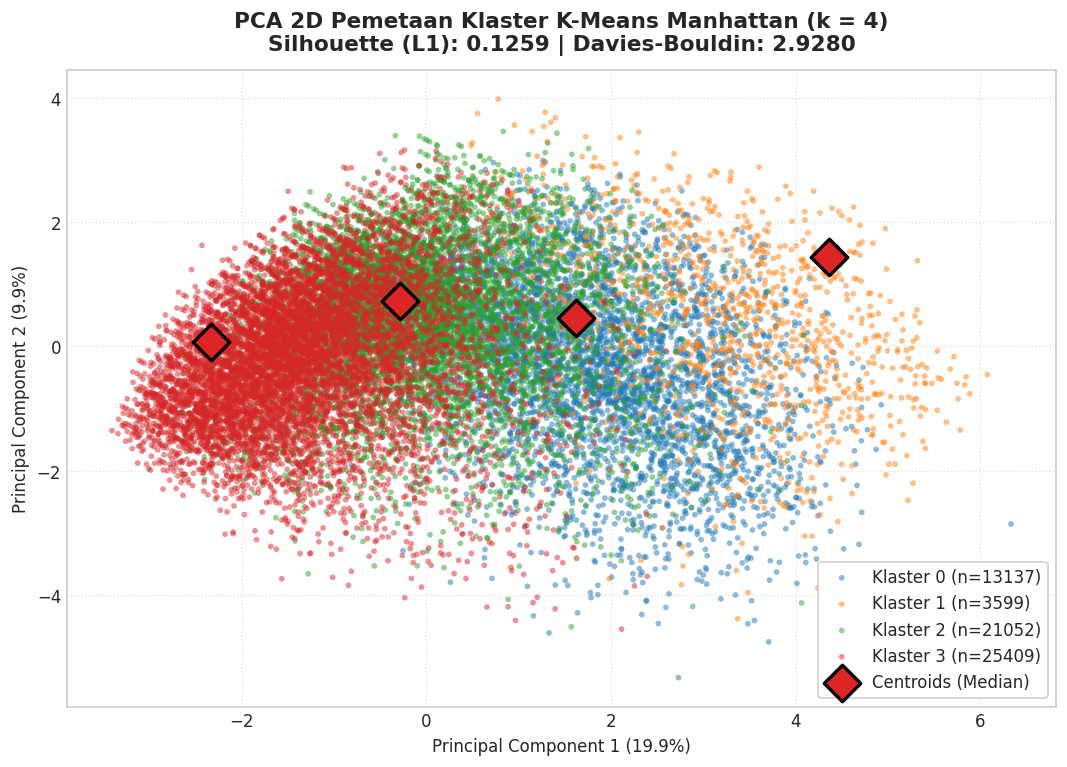

In [ ]:
# Visualisasi
pca = PCA(n_components=2, random_state=RANDOM_STATE)  # PCA ke 2 dimensi
X_pca = pca.fit_transform(X_scaled)
centroids_pca = pca.transform(model_manhattan.centroids)  # proyeksikan centroid ke ruang 2D yang sama

rng_plot = np.random.RandomState(RANDOM_STATE)
n_plot = min(20000, len(X_pca))  # gambar maksimal 20.000 titik biar ringan
idx_plot = rng_plot.choice(len(X_pca), size=n_plot, replace=False)

plt.figure(figsize=(9, 6.5))
palette = sns.color_palette("tab10", optimal_k)

for k in range(optimal_k):
    mask = (labels[idx_plot] == k)  # titik sampel yang masuk klaster k
    plt.scatter(
        X_pca[idx_plot][mask, 0], X_pca[idx_plot][mask, 1],
        color=palette[k],
        label=f'Klaster {k} (n={np.sum(labels == k)})',
        alpha=0.5, s=12, edgecolors='none'
    )

plt.scatter(
    centroids_pca[:, 0], centroids_pca[:, 1],
    marker='D', s=240, c='#DC2626',
    edgecolor='black', linewidth=2,
    label='Centroids (Median)', zorder=10
)

plt.title(f'PCA 2D Pemetaan Klaster K-Means Manhattan (k = {optimal_k})\n'
          f'Silhouette (L1): {sil_score:.4f} | Davies-Bouldin: {db_score:.4f}',
          fontsize=13, fontweight='bold', pad=12)
plt.xlabel(f'Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(frameon=True, facecolor='white', framealpha=0.9, loc='best')
plt.tight_layout()

cluster_path = os.path.join(OUTPUT_DIR, "cluster_manhattan.png")
plt.savefig(cluster_path, dpi=300)
print(f"[SIMPAN] Grafik pemetaan klaster disimpan ke: '{cluster_path}'")
plt.show()

In [ ]:
# Fitur paling berpengaruh
loadings = pd.DataFrame(pca.components_.T, index=df_features.columns, columns=['PC1', 'PC2'])  # bobot fitur di tiap PC
print("Fitur paling berpengaruh di PC1:")
print(loadings['PC1'].abs().sort_values(ascending=False).head(6).round(3))  # 6 teratas PC1
print("\nFitur paling berpengaruh di PC2:")
print(loadings['PC2'].abs().sort_values(ascending=False).head(6).round(3))  # 6 teratas PC2

Fitur paling berpengaruh di PC1:
GenHlth                 0.441
DiffWalk                0.408
PhysHlth                0.398
HighBP                  0.295
HeartDiseaseorAttack    0.264
PhysActivity            0.241
Name: PC1, dtype: float64

Fitur paling berpengaruh di PC2:
Age                     0.524
MentHlth                0.417
HighBP                  0.327
HeartDiseaseorAttack    0.308
HighChol                0.286
PhysHlth                0.256
Name: PC2, dtype: float64


In [ ]:
# ===== ARI & NMI vs label Diabetes_binary =====
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

ALGO_NAME, METRIK_NAME = 'K-Medians', 'Manhattan'

y_true = y_sample.values if 'y_sample' in globals() else y_label.values
lab = np.asarray(labels)
mk = lab != -1                                    # K-Means: semua True (tidak ada noise)

hasil_ext = pd.DataFrame([{
    'Algoritma': ALGO_NAME, 'Metrik': METRIK_NAME,
    'ARI (non-noise)':   round(adjusted_rand_score(y_true[mk], lab[mk]), 4),
    'NMI (non-noise)':   round(normalized_mutual_info_score(y_true[mk], lab[mk]), 4),
    'ARI (semua titik)': round(adjusted_rand_score(y_true, lab), 4),   # noise = 1 label (-1)
    'NMI (semua titik)': round(normalized_mutual_info_score(y_true, lab), 4),
}])
print(hasil_ext.to_string(index=False))

out = globals().get('OUTPUT_DIR', '.')
hasil_ext.to_excel(os.path.join(out, f'ari_nmi_{ALGO_NAME.lower()}_{METRIK_NAME.lower()}.xlsx'), index=False)

Algoritma    Metrik  ARI (non-noise)  NMI (non-noise)  ARI (semua titik)  NMI (semua titik)
K-Medians Manhattan           0.0585           0.0635             0.0585             0.0635
